# Clean Taiko preprocessing: scanner manifest → CNN–LSTM tensors

Run this notebook on PACE after `scan_dataset.py` has written `manifest_strict.csv`. Each numbered section is one preprocessing stage.

## 0. Configure paths and experiment settings

In [33]:
from pathlib import Path
import pandas as pd

print("Working directory:", Path.cwd())

manifest = pd.read_csv("manifest_with_split.csv")

print("Total rows:", len(manifest))
print(manifest["status"].value_counts())
print(manifest["split"].value_counts(dropna=False))
print("Columns:", manifest.columns.tolist())

Working directory: /storage/ice1/8/2/ykim3001/CS7643
Total rows: 1763
status
accepted    1763
Name: count, dtype: int64
split
train         1411
test           178
validation     174
Name: count, dtype: int64
Columns: ['title', 'tja', 'audio', 'bpm', 'offset', 'oni_sections', 'playable_notes', 'has_measure', 'count_1', 'count_2', 'count_3', 'count_4', 'count_A', 'count_B', 'count_5', 'count_6', 'count_7', 'count_8', 'count_9', 'status', 'reason', 'split']


In [34]:
from pathlib import Path

print("Current directory:", Path.cwd())

ese = Path("ESE")
print("ESE exists:", ese.exists())

for p in list(ese.iterdir())[:15]:
    print(p)

Current directory: /storage/ice1/8/2/ykim3001/CS7643
ESE exists: True
ESE/tjavalidator.py
ESE/README.md
ESE/05 Variety
ESE/09 Namco Original
ESE/10 Taiko Towers
ESE/01 Pop
ESE/03 Vocaloid
ESE/04 Children and Folk
ESE/02 Anime
ESE/box.def
ESE/.git
ESE/06 Classical
ESE/11 Dan Dojo
ESE/08 Live Festival Mode
ESE/07 Game Music


In [35]:
# convert root path to mine

from pathlib import Path
import pandas as pd

old_root = "/home/hice1/plaperche3/scratch/ESE/"
new_root = str(Path("ESE").resolve()) + "/"

manifest = pd.read_csv("manifest_with_split.csv")

for col in ["tja", "audio"]:
    manifest[col] = manifest[col].str.replace(
        old_root, new_root, regex=False
    )

for col in ["tja", "audio"]:
    exists = manifest[col].apply(lambda p: Path(p).is_file())
    print(f"{col}: {exists.sum()}/{len(manifest)} files found")

if all(manifest[col].apply(lambda p: Path(p).is_file()).all()
       for col in ["tja", "audio"]):
    manifest.to_csv("manifest_with_split.csv", index=False)
    print("All paths updated successfully!")
else:
    print("Some files are missing. CSV not overwritten.")

tja: 1763/1763 files found
audio: 1763/1763 files found
All paths updated successfully!


In [36]:
from pathlib import Path

for i, row in manifest.head(5).iterrows():
    tja = Path(row["tja"])
    audio = Path(row["audio"])

    print(f"Chart {i}")
    print("  TJA:", tja, "| Exists:", tja.exists())
    print("  Audio:", audio, "| Exists:", audio.exists())

Chart 0
  TJA: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/LOVE and ENERGY/LOVE and ENERGY.tja | Exists: True
  Audio: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/LOVE and ENERGY/LOVE and ENERGY.ogg | Exists: True
Chart 1
  TJA: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/Utakata Ai no Mahoroba/Utakata Ai no Mahoroba.tja | Exists: True
  Audio: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/Utakata Ai no Mahoroba/Utakata Ai no Mahoroba.ogg | Exists: True
Chart 2
  TJA: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/Itadaki Babel/Itadaki Babel.tja | Exists: True
  Audio: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/Itadaki Babel/Itadaki Babel.ogg | Exists: True
Chart 3
  TJA: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/ALiVE/ALiVE.tja | Exists: True
  Audio: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/ALiVE/ALiVE.ogg | Exists: True
Chart 4
  TJA: /storage/ice1/8/2/ykim3001/CS7643/ESE/05 Variety/Honoo no Fighter/Honoo no Fighter.tja | Exists: True
  Audio

In [37]:
from pathlib import Path
print(Path.cwd())

/storage/ice1/8/2/ykim3001/CS7643


In [38]:
from pathlib import Path
import csv, json, subprocess
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = Path("/storage/ice1/8/2/ykim3001/CS7643")
# MANIFEST_PATH = Path("selected_15.csv")
# OUTPUT_DIR = Path("processed_10")
MANIFEST_PATH = Path("manifest_with_split.csv")
OUTPUT_DIR = Path("processed_full")

SEED, N_SONGS = 42, 1763 #10
RUN_PIPELINE = True

SR, FRAME_MS, N_MELS = 44100, 23, 80
MEL_LO, MEL_HI, LOG_EPS = 27.5, 16000.0, 1e-16

CLASS_NAMES = ["none", "don", "ka", "DON", "KA", "drumroll", "denden"]

ONSET = {"1": 1, "2": 2, "3": 3, "A": 3, "4": 4, "B": 4}
LONG_START = {"5": 5, "6": 5, "7": 6, "9": 6}

FORBIDDEN_COMMANDS = {
    "BPMCHANGE", "DELAY", "BRANCHSTART", "BRANCHEND", "N", "E", "M"
}

ALLOWED_COMMANDS = {
    "MEASURE", "GOGOSTART", "GOGOEND",
    "SCROLL", "BARLINEON", "BARLINEOFF"
}

## 1. Load scanner-approved charts

Only `status == accepted` rows are eligible. Paths in the PACE manifest can be absolute or relative to `DATA_ROOT`.

In [39]:
def resolve_from_root(value):
    path = Path(value)
    return path if path.is_absolute() else DATA_ROOT / path


def load_accepted_rows():
    manifest_path = resolve_from_root(MANIFEST_PATH)

    if not manifest_path.is_file():
        raise FileNotFoundError(
            f"Selected-song manifest not found: {manifest_path.resolve()}"
        )

    with manifest_path.open(encoding="utf-8", newline="") as handle:
        rows = [
            row
            for row in csv.DictReader(handle)
            if row["status"] == "accepted"
        ]

    if len(rows) < N_SONGS:
        raise ValueError(
            f"Need {N_SONGS} accepted charts; found {len(rows)} in {manifest_path}."
        )

    return rows


accepted_rows = load_accepted_rows()
selected_rows = accepted_rows

print(f"Accepted charts available: {len(accepted_rows)}")
print(f"Using first {len(selected_rows)} selected charts:")

for i, row in enumerate(selected_rows, 1):
    print(f"{i:2d}. {row['title']}")

Accepted charts available: 1763
Using first 1763 selected charts:
 1. LOVE & ENERGY
 2. Utakata, Ai no Mahoroba
 3. Itadaki Babel (Prod. Kenmochi Hidefumi)
 4. ALiVE
 5. Honoo no Fighter -Inoki Bombaye- -New Audio/Chart-
 6. Indiana Jones Theme
 7. Doctor X Theme
 8. Matsuyoi Night Bug
 9. Help me, ERINNNNNN!! -Cranky remix-
10. Hypnosis Mic -Division Battle Anthem-
11. TRUTH
12. Help me, Saitama 2000!!
13. Mani Mani(Prod.TAKU INOUE)
14. Favorite Days
15. Ninja Batman Theme
16. Hanatsukiyo
17. Necrofantasia ～Demetori Arrange～
18. Deep Cleansing
19. LONELY ROLLING STAR[picco Remix]
20. Hyper Bass (feat. Yunomi)
21. CoroCoro Comic 40th Anniversary Song
22. Theme of Naoki Hanzawa ~Main Title~
23. Inscrutable Battle
24. GAME CHANGER
25. Jamboree Mickey!
26. WE ARE THE CHAMP ～THE NAME OF THE GAME～
27. Bakuretsu Thaumazein (Prod. ChibaNyan)
28. Connected World
29. good night baby (feat. Moe Shop)
30. WARNING × WARNING × WARNING
31. Battle Without Honor or Humanity
32. Ama-chan Opening Theme


## 2. Select ten songs and make the song-level split

The split happens before feature normalization. No frames from a validation/test song may be used to fit normalization.

We need the validation set for model selection, so we keep a separate test set for an unbiased final comparison between the CNN-LSTM and Transformer.

In [40]:
# selected_rows = accepted_rows[:N_SONGS]

# for index, row in enumerate(selected_rows):
#     row["song_id"] = f"{index:02d}_{Path(row['tja']).stem}"
#     row["tja_path"] = resolve_from_root(row["tja"])
#     row["audio_path"] = resolve_from_root(row["audio"])

# ids = [row["song_id"] for row in selected_rows]

# split = {
#     "seed": SEED,
#     "train": ids[:8],
#     "validation": ids[8:9],
#     "test": ids[9:10],
# }

# for row in selected_rows:
#     if row["song_id"] in split["train"]:
#         row["split"] = "train"
#     elif row["song_id"] in split["validation"]:
#         row["split"] = "validation"
#     else:
#         row["split"] = "test"

#     print(f"{row['split']:10s} {row['song_id']} | {row['title']}")

selected_rows = accepted_rows

split = {
    "seed": SEED,
    "train": [],
    "validation": [],
    "test": []
}

for index, row in enumerate(selected_rows):
    row["song_id"] = f"{index:04d}_{Path(row['tja']).stem}"
    row["tja_path"] = resolve_from_root(row["tja"])
    row["audio_path"] = resolve_from_root(row["audio"])

    split[row["split"]].append(row["song_id"])

    print(f"{row['split']:10s} {row['song_id']} | {row['title']}")

train      0000_LOVE and ENERGY | LOVE & ENERGY
train      0001_Utakata Ai no Mahoroba | Utakata, Ai no Mahoroba
train      0002_Itadaki Babel | Itadaki Babel (Prod. Kenmochi Hidefumi)
train      0003_ALiVE | ALiVE
train      0004_Honoo no Fighter | Honoo no Fighter -Inoki Bombaye- -New Audio/Chart-
train      0005_Indiana Jones Theme | Indiana Jones Theme
train      0006_Doctor X Theme | Doctor X Theme
train      0007_Matsuyoi Night Bug | Matsuyoi Night Bug
train      0008_Help me ERINNNNNN Cranky Remix | Help me, ERINNNNNN!! -Cranky remix-
validation 0009_Hypnosis Mic Division Battle Anthem | Hypnosis Mic -Division Battle Anthem-
train      0010_TRUTH | TRUTH
train      0011_Help me Saitama 2000 | Help me, Saitama 2000!!
train      0012_Mani Mani | Mani Mani(Prod.TAKU INOUE)
test       0013_Favorite Days | Favorite Days
train      0014_Ninja Batman Theme | Ninja Batman Theme
train      0015_Hanatsukiyo | Hanatsukiyo
train      0016_Necrofantasia Demetori Arrange | Necrofantasia ～Deme

validation 1055_Escatumbararibe | Escatumbararibê
train      1056_Tankou Bushi | Tankou Bushi
train      1057_Kumamoto Surprise Kumamon Gymnastics | Kumamoto Surprise! Kumamon Gymnastics
train      1058_Jingle Bells | Jingle Bells
train      1059_Mashin Sentai Kiramager | Mashin Sentai Kiramager
train      1060_Ohayou Mellchan | Good morning MELL-Chan
train      1061_Walking on the Railroad | Walking on the Railroad
validation 1062_Himitsukituber | Himitsuki-tuber
train      1063_Kisoutengai Fushigi wo Douzo | Kisoutengai Fushigi wo Douzo
train      1064_Ore Koso Only One | Ore Koso Only One
train      1065_Xiao Maolu | Xiao Maolu
validation 1066_Papa Mama Mc | Papa Mama Mc
validation 1067_Hakone Hachisato no Hanjirou | Hakone Hachisato no Hanjirou
validation 1068_Omocha no Chachacha New Audio | Omocha no Cha-cha-cha -New Audio-
validation 1069_Omocha no Chachacha Old Audio | Omocha no Cha-cha-cha -Old Audio-
train      1070_Inu no Omawarisan | Inu no Omawari-san
train      1071_Papa M

## 3. Decode audio and make chronological 23 ms chunks

In [41]:
def load_mono_audio(path):
    result = subprocess.run(
        [FFMPEG, "-v", "error", "-i", str(path), "-ac", "1", "-ar", str(SR), "-f", "f32le", "-"],
        capture_output=True, check=True,
    )
    return np.frombuffer(result.stdout, dtype=np.float32)

def make_chunks(audio):
    duration_ms = len(audio) * 1000 / SR
    count = int(duration_ms // FRAME_MS)

    return [
        audio[
            int(k * FRAME_MS * SR / 1000):
            int((k + 1) * FRAME_MS * SR / 1000)
        ]
        for k in range(count)
    ]

## 4. Convert audio chunks to raw 80-band log-Mel features

In [42]:
_windows, _filterbanks = {}, {}
def hz_to_mel(freq): return 2595.0 * np.log10(1.0 + freq / 700.0)

def log_mel_features(audio_path):
    output = []
    for chunk in make_chunks(load_mono_audio(audio_path)):
        if len(chunk) < 4:
            output.append(np.zeros(N_MELS)); continue
        n = len(chunk)
        if n not in _windows:
            phase = 2 * np.pi * np.arange(n) / (n - 1)
            window = .44959 - .49364 * np.cos(phase) + .05677 * np.cos(2 * phase)
            _windows[n] = window * 2 / window.sum()
        y = np.roll(chunk * _windows[n], -(n // 2))
        if n % 2: y = np.delete(y, n // 2)
        power = np.abs(np.fft.rfft(y)) ** 2
        bins = len(power)
        if bins not in _filterbanks:
            edges = np.linspace(hz_to_mel(MEL_LO), hz_to_mel(MEL_HI), N_MELS + 2)
            bin_mels = hz_to_mel(np.arange(bins) * SR / 2 / (bins - 1))
            bank = np.zeros((N_MELS, bins))
            for i in range(N_MELS):
                left, center, right = edges[i:i+3]
                bank[i] = np.clip(np.minimum((bin_mels-left)/(center-left), (right-bin_mels)/(right-center)), 0, None)
                bank[i] /= bank[i].sum()
            _filterbanks[bins] = bank
        output.append(_filterbanks[bins] @ power)
    return np.log(np.asarray(output) + LOG_EPS).astype(np.float32)

## 5. TJA parser for accepted Oni charts

This is a second safety gate: it accepts `#MEASURE`, ignores visual commands, and raises an error for timing-changing or unknown commands.

This translates the TJA chart into timed musical events

In [43]:
def header_value(text, key):
    for raw in text.splitlines():
        line = raw.split("//", 1)[0].strip()
        if ":" in line:
            name, value = line.split(":", 1)
            if name.strip().upper() == key.upper():
                return value.strip()
    return None


def parse_events(path):
    text = path.read_text(encoding="utf-8-sig")

    bpm = float(header_value(text, "BPM"))
    offset = float(header_value(text, "OFFSET") or 0)

    course = None
    active = False
    body = []

    for raw in text.splitlines():
        line = raw.split("//", 1)[0].strip()

        if not line:
            continue

        if ":" in line:
            name, value = line.split(":", 1)

            if name.strip().upper() == "COURSE":
                course = value.strip().lower()
                continue

        upper = line.upper()

        if upper.startswith("#START"):
            active = course in {"oni", "3"}
            continue

        if upper.startswith("#END"):
            active = False
            continue

        if active:
            body.append(line)

    if not body:
        raise ValueError(f"{path}: no Oni body")

    time = -offset
    beats_per_measure = 4.0
    events = []
    opened = None
    measure_notes = []

    def process_measure():
        nonlocal time, opened, measure_notes

        if not measure_notes:
            time += beats_per_measure * 60.0 / bpm
            return

        measure_duration = beats_per_measure * 60.0 / bpm
        step = measure_duration / len(measure_notes)

        for note in measure_notes:
            if note == "8":
                if opened is None:
                    raise ValueError(f"{path}: unmatched 8")

                events.append((opened[0], opened[1], time))
                opened = None

            elif note in LONG_START:
                if opened is not None:
                    raise ValueError(f"{path}: nested long note")

                opened = (time, LONG_START[note])

            elif note in ONSET:
                if opened is not None:
                    raise ValueError(f"{path}: note inside long note")

                events.append((time, ONSET[note], None))

            elif note != "0":
                raise ValueError(f"{path}: unsupported note {note!r}")

            time += step

    for line in body:
        if line.startswith("#"):
            name, _, argument = line[1:].partition(" ")
            name = name.upper()
            argument = argument.strip()

            if name in FORBIDDEN_COMMANDS:
                raise ValueError(f"{path}: forbidden #{name}")

            if name == "MEASURE":
                num, den = argument.split("/")
                beats_per_measure = 4.0 * float(num) / float(den)

            elif name not in ALLOWED_COMMANDS:
                raise ValueError(f"{path}: unsupported #{name}")

            continue

        for char in line:
            if char == ",":
                process_measure()
                measure_notes = []

            elif not char.isspace():
                measure_notes.append(char.upper())

    if measure_notes:
        process_measure()

    if opened is not None:
        raise ValueError(f"{path}: unclosed long note")

    return events

## 6. Align events to the audio timeline and make one-hot labels

output will look like:
| 23 ms Frame | Audio           | Chart               |
|-------------|-----------------|---------------------|
| Frame 0     | 80 Mel features | `[1,0,0,0,0,0,0]`   |
| Frame 1     | 80 Mel features | `[1,0,0,0,0,0,0]`   |
| Frame 2     | 80 Mel features | `[0,1,0,0,0,0,0]` ← Don |
| Frame 3     | 80 Mel features | `[1,0,0,0,0,0,0]`   |
| Frame 4     | 80 Mel features | `[0,0,1,0,0,0,0]` ← Ka |

In [44]:
def events_to_labels(events, n_frames):
    labels = np.zeros(n_frames, dtype=np.int64)
    dropped = 0
    for start, cls, end in events:
        first = int(start * 1000 // FRAME_MS)
        if not 0 <= first < n_frames: dropped += 1; continue
        if end is None:
            if labels[first]: dropped += 1
            else: labels[first] = cls
        else:
            last = min(int(end * 1000 // FRAME_MS), n_frames - 1)
            span = labels[first:last + 1]
            span[span == 0] = cls
    if dropped: raise ValueError(f"{dropped} out-of-range or overlapping events")
    return np.eye(7, dtype=np.int32)[labels]

# Validate audio/chart alignment before preprocessing.
There are few songs that TJA chart contained notes scheduled after the audio had already ended.

In [45]:

import subprocess
import json
import re
from pathlib import Path
import imageio_ffmpeg

FFMPEG = imageio_ffmpeg.get_ffmpeg_exe()

# ============================================================
# 1. Get audio duration without decoding the entire audio
# ============================================================

def get_audio_duration_fast(audio_path):
    result = subprocess.run(
        [
            FFMPEG,
            "-hide_banner",
            "-i", str(audio_path),
        ],
        capture_output=True,
        text=True,
    )

    match = re.search(
        r"Duration:\s*(\d+):(\d+):([\d.]+)",
        result.stderr
    )

    if match is None:
        raise ValueError(
            f"Cannot read audio duration: {audio_path}"
        )

    hours, minutes, seconds = match.groups()

    return (
        int(hours) * 3600
        + int(minutes) * 60
        + float(seconds)
    )


# ============================================================
# 2. Validate songs
# ============================================================

# IMPORTANT:
# Run the original CSV-loading / selected_rows creation cell
# before running this cell.
#
# This should start with all 1763 songs.

original_rows = selected_rows.copy()

valid_rows = []
rejected_rows = []

total = len(original_rows)

print(f"Total songs to check: {total}", flush=True)

for i, row in enumerate(original_rows, 1):
    try:
        duration = get_audio_duration_fast(
            row["audio_path"]
        )

        events = parse_events(
            row["tja_path"]
        )

        invalid = [
            (start, cls, end)
            for start, cls, end in events
            if (
                start < 0
                or start >= duration
                or (end is not None and end > duration)
            )
        ]

        if invalid:
            rejected_rows.append({
                "song_id": row["song_id"],
                "reason": "chart_exceeds_audio",
                "invalid_events": len(invalid),
                "audio_duration": duration,
            })
        else:
            valid_rows.append(row)

    except Exception as e:
        rejected_rows.append({
            "song_id": row.get("song_id", ""),
            "reason": f"{type(e).__name__}: {e}",
        })

    if i % 50 == 0 or i == total:
        print(
            f"Checked {i}/{total}",
            flush=True
        )


# ============================================================
# 3. Keep only valid songs
# ============================================================

selected_rows = valid_rows


# ============================================================
# 4. Save rejected songs
# ============================================================

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

rejected_path = OUTPUT_DIR / "rejected_alignment.json"

rejected_path.write_text(
    json.dumps(
        rejected_rows,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


# ============================================================
# 5. Print full validation summary
# ============================================================

print("\n========== VALIDATION SUMMARY ==========")

print(f"Total songs: {total}")
print(f"Accepted: {len(valid_rows)}")
print(f"Rejected: {len(rejected_rows)}")

print("\nExcluded songs:")

if rejected_rows:
    for row in rejected_rows:
        print(
            f"- {row['song_id']}"
            f" | {row['reason']}"
        )
else:
    print("None")

print("\nRejection log saved to:")
print(rejected_path)

print("\nReady for preprocessing!")


Total songs to check: 1763
Checked 50/1763
Checked 100/1763
Checked 150/1763
Checked 200/1763
Checked 250/1763
Checked 300/1763
Checked 350/1763
Checked 400/1763
Checked 450/1763
Checked 500/1763
Checked 550/1763
Checked 600/1763
Checked 650/1763
Checked 700/1763
Checked 750/1763
Checked 800/1763
Checked 850/1763
Checked 900/1763
Checked 950/1763
Checked 1000/1763
Checked 1050/1763
Checked 1100/1763
Checked 1150/1763
Checked 1200/1763
Checked 1250/1763
Checked 1300/1763
Checked 1350/1763
Checked 1400/1763
Checked 1450/1763
Checked 1500/1763
Checked 1550/1763
Checked 1600/1763
Checked 1650/1763
Checked 1700/1763
Checked 1750/1763
Checked 1763/1763

========== VALIDATION SUMMARY ==========
Total songs: 1763
Accepted: 1761
Rejected: 2

Excluded songs:
- 0417_Soba ni Iru ne | chart_exceeds_audio
- 1236_CHALA HEADCHALA Older Audio | chart_exceeds_audio

Rejection log saved to:
processed_full/rejected_alignment.json

Ready for preprocessing!


## 7. Extract and save raw artifacts per song

Raw features are saved before normalization, along with labels and metadata.

In [46]:
raw_data = {}

if RUN_PIPELINE:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    raw_root = OUTPUT_DIR / "raw"
    raw_root.mkdir(parents=True, exist_ok=True)

    for row in selected_rows:
        song_id = row["song_id"]

        print(f"Processing {song_id}...")

        features_raw = log_mel_features(row["audio_path"])
        events = parse_events(row["tja_path"])
        labels = events_to_labels(events, len(features_raw))

        if not np.isfinite(features_raw).all():
            raise ValueError(f"{song_id}: non-finite audio features")

        if not np.all(labels.sum(axis=1) == 1):
            raise ValueError(f"{song_id}: invalid one-hot labels")

        folder = raw_root / song_id
        folder.mkdir(parents=True, exist_ok=True)

        np.save(folder / "features_raw.npy", features_raw)
        np.save(folder / "labels.npy", labels)

        metadata = {
            **{
                k: str(v)
                for k, v in row.items()
                if k not in {"tja_path", "audio_path"}
            },
            "tja_path": str(row["tja_path"]),
            "audio_path": str(row["audio_path"]),
            "frames": len(features_raw),
            "events": len(events),
            "class_counts": labels.sum(axis=0).tolist()
        }

        (folder / "metadata.json").write_text(
            json.dumps(metadata, indent=2)
        )

        raw_data[song_id] = (features_raw, labels)

        print(
            f"  features={features_raw.shape}, "
            f"labels={labels.shape}, "
            f"events={len(events)}"
        )

    (OUTPUT_DIR / "split.json").write_text(
        json.dumps(split, indent=2)
    )

    print(f"Saved raw data for {len(raw_data)} songs.")

else:
    print("Set RUN_PIPELINE=True to extract raw artifacts.")

Processing 0000_LOVE and ENERGY...
  features=(6007, 80), labels=(6007, 7), events=502
Processing 0001_Utakata Ai no Mahoroba...
  features=(5348, 80), labels=(5348, 7), events=640
Processing 0002_Itadaki Babel...
  features=(4765, 80), labels=(4765, 7), events=499
Processing 0003_ALiVE...
  features=(5584, 80), labels=(5584, 7), events=832
Processing 0004_Honoo no Fighter...
  features=(4460, 80), labels=(4460, 7), events=412
Processing 0005_Indiana Jones Theme...
  features=(6353, 80), labels=(6353, 7), events=499
Processing 0006_Doctor X Theme...
  features=(7187, 80), labels=(7187, 7), events=645
Processing 0007_Matsuyoi Night Bug...
  features=(5782, 80), labels=(5782, 7), events=689
Processing 0008_Help me ERINNNNNN Cranky Remix...
  features=(5261, 80), labels=(5261, 7), events=684
Processing 0009_Hypnosis Mic Division Battle Anthem...
  features=(14235, 80), labels=(14235, 7), events=1629
Processing 0010_TRUTH...
  features=(4975, 80), labels=(4975, 7), events=487
Processing 00

  features=(3674, 80), labels=(3674, 7), events=272
Processing 0093_Sugar Song to Bitter Step...
  features=(4920, 80), labels=(4920, 7), events=536
Processing 0094_Say Something...
  features=(5631, 80), labels=(5631, 7), events=298
Processing 0095_Smile and Go...
  features=(4440, 80), labels=(4440, 7), events=500
Processing 0096_Edison...
  features=(4783, 80), labels=(4783, 7), events=505
Processing 0097_Mottai Night Land...
  features=(4900, 80), labels=(4900, 7), events=457
Processing 0098_Ora Tokyosa Iguda...
  features=(5257, 80), labels=(5257, 7), events=501
Processing 0099_Taotai...
  features=(5484, 80), labels=(5484, 7), events=177
Processing 0100_CITRUS...
  features=(4332, 80), labels=(4332, 7), events=301
Processing 0101_Minna Ga Minna Eiyuu...
  features=(3147, 80), labels=(3147, 7), events=243
Processing 0102_Sil vous President...
  features=(4032, 80), labels=(4032, 7), events=444
Processing 0103_Watashi Igai Watashi ja Nai no...
  features=(3840, 80), labels=(3840, 7

  features=(4245, 80), labels=(4245, 7), events=412
Processing 0189_NON STOP...
  features=(4782, 80), labels=(4782, 7), events=420
Processing 0190_believe in you...
  features=(3967, 80), labels=(3967, 7), events=316
Processing 0191_RIVER...
  features=(5221, 80), labels=(5221, 7), events=414
Processing 0192_Flying Get...
  features=(4482, 80), labels=(4482, 7), events=310
Processing 0193_AIAIAI...
  features=(4515, 80), labels=(4515, 7), events=399
Processing 0194_Saudade...
  features=(4354, 80), labels=(4354, 7), events=338
Processing 0195_PIECES OF A DREAM...
  features=(5401, 80), labels=(5401, 7), events=275
Processing 0196_Last Christmas...
  features=(6632, 80), labels=(6632, 7), events=526
Processing 0197_Ichizu...
  features=(4001, 80), labels=(4001, 7), events=497
Processing 0198_Kimi ga Iru...
  features=(5273, 80), labels=(5273, 7), events=595
Processing 0199_Zhong Guo Hua...
  features=(5483, 80), labels=(5483, 7), events=576
Processing 0200_Frienger...
  features=(3505,

  features=(4080, 80), labels=(4080, 7), events=227
Processing 0284_Byoushin wo Kamu...
  features=(4257, 80), labels=(4257, 7), events=404
Processing 0285_GODSONG...
  features=(5343, 80), labels=(5343, 7), events=648
Processing 0286_Ki ga Tsukeba Anata...
  features=(5229, 80), labels=(5229, 7), events=391
Processing 0287_traveling...
  features=(5246, 80), labels=(5246, 7), events=391
Processing 0288_true blue...
  features=(4070, 80), labels=(4070, 7), events=316
Processing 0289_independent...
  features=(4731, 80), labels=(4731, 7), events=454
Processing 0290_Ai no Hana...
  features=(3305, 80), labels=(3305, 7), events=270
Processing 0291_Honmayade Nandeyanen Shirankedo...
  features=(5813, 80), labels=(5813, 7), events=602
Processing 0292_Iroha Step...
  features=(5675, 80), labels=(5675, 7), events=544
Processing 0293_Promise the Star...
  features=(4861, 80), labels=(4861, 7), events=338
Processing 0294_Karon...
  features=(4237, 80), labels=(4237, 7), events=375
Processing 02

  features=(4754, 80), labels=(4754, 7), events=405
Processing 0380_Love Song wa Tomaranai yo...
  features=(4941, 80), labels=(4941, 7), events=432
Processing 0381_Marksman...
  features=(4865, 80), labels=(4865, 7), events=411
Processing 0382_Just Dance...
  features=(3928, 80), labels=(3928, 7), events=343
Processing 0383_Ni Zhan...
  features=(4092, 80), labels=(4092, 7), events=338
Processing 0384_Girls and Boys...
  features=(4211, 80), labels=(4211, 7), events=389
Processing 0385_Gokuraku Joudo...
  features=(3603, 80), labels=(3603, 7), events=303
Processing 0386_Makenaide...
  features=(3590, 80), labels=(3590, 7), events=171
Processing 0387_Bye My Melody...
  features=(5201, 80), labels=(5201, 7), events=438
Processing 0388_Nakanaide...
  features=(3533, 80), labels=(3533, 7), events=274
Processing 0389_Miss You 3000...
  features=(4020, 80), labels=(4020, 7), events=212
Processing 0390_Savage Love...
  features=(3542, 80), labels=(3542, 7), events=275
Processing 0391_Marine 

...

  features=(5001, 80), labels=(5001, 7), events=655
Processing 1322_Lets Fresh Pretty Cure...
  features=(3816, 80), labels=(3816, 7), events=311
Processing 1323_Kumon Kourin Magical Force...
  features=(4127, 80), labels=(4127, 7), events=448
Processing 1324_Pretty Cure 5 Full Throttle GO GO...
  features=(3730, 80), labels=(3730, 7), events=414
Processing 1325_NATSU Shiyouze...
  features=(4667, 80), labels=(4667, 7), events=380
Processing 1326_Toki o Matou...
  features=(4495, 80), labels=(4495, 7), events=389
Processing 1327_Boku Doraemon...
  features=(4127, 80), labels=(4127, 7), events=320
Processing 1328_Allegro Cantabile...
  features=(3646, 80), labels=(3646, 7), events=381
Processing 1329_Best Wishes...
  features=(3985, 80), labels=(3985, 7), events=331
Processing 1330_Sousei no Aquarion...
  features=(4015, 80), labels=(4015, 7), events=364
Processing 1331_Spurt Syndromer...
  features=(3915, 80), labels=(3915, 7), events=478
Processing 1332_CARMINE...
  features=(3992, 80

  features=(5485, 80), labels=(5485, 7), events=414
Processing 1416_Aozora no Rhapsody...
  features=(4055, 80), labels=(4055, 7), events=513
Processing 1417_Tokusou Sentai Dekaranger...
  features=(3929, 80), labels=(3929, 7), events=380
Processing 1418_Kagerou...
  features=(3895, 80), labels=(3895, 7), events=416
Processing 1419_DiSCOVER THE FUTURE...
  features=(4175, 80), labels=(4175, 7), events=301
Processing 1420_Hacking to the Gate...
  features=(4049, 80), labels=(4049, 7), events=363
Processing 1421_Mirai Connection...
  features=(3824, 80), labels=(3824, 7), events=339
Processing 1422_BLUE SAPPHIRE...
  features=(4264, 80), labels=(4264, 7), events=305
Processing 1423_Kakumei Douchuu...
  features=(4001, 80), labels=(4001, 7), events=440
Processing 1424_Kirari Star Twinkle Pretty Cure...
  features=(3977, 80), labels=(3977, 7), events=296
Processing 1425_Lupin III Theme 78 New Audio...
  features=(3732, 80), labels=(3732, 7), events=325
Processing 1426_Lupin III Theme 78 Ol

  features=(4098, 80), labels=(4098, 7), events=419
Processing 1510_GO New Audio...
  features=(4017, 80), labels=(4017, 7), events=419
Processing 1511_Busters Ready Go...
  features=(3154, 80), labels=(3154, 7), events=231
Processing 1512_Dang Dang...
  features=(3618, 80), labels=(3618, 7), events=403
Processing 1513_JUST LIVE MORE...
  features=(3166, 80), labels=(3166, 7), events=330
Processing 1514_Renacer Serenade...
  features=(3954, 80), labels=(3954, 7), events=414
Processing 1515_Kurakura...
  features=(3928, 80), labels=(3928, 7), events=459
Processing 1516_Ressha Sentai ToQger...
  features=(3558, 80), labels=(3558, 7), events=270
Processing 1517_Jounetsu de Mune Atsu...
  features=(3797, 80), labels=(3797, 7), events=311
Processing 1518_Cry Baby...
  features=(4059, 80), labels=(4059, 7), events=334
Processing 1519_Cry Baby cover...
  features=(4092, 80), labels=(4092, 7), events=334
Processing 1520_Tan Tan Taan...
  features=(4020, 80), labels=(4020, 7), events=345
Proces

  features=(6903, 80), labels=(6903, 7), events=992
Processing 1602_Sora...
  features=(5426, 80), labels=(5426, 7), events=435
Processing 1603_Mitsuboshi...
  features=(5803, 80), labels=(5803, 7), events=467
Processing 1604_Balloon Fight Balloon Trip...
  features=(4815, 80), labels=(4815, 7), events=538
Processing 1605_Lightning Dance...
  features=(7033, 80), labels=(7033, 7), events=713
Processing 1606_Flower Girl...
  features=(5489, 80), labels=(5489, 7), events=575
Processing 1607_We Have A Dream...
  features=(5455, 80), labels=(5455, 7), events=607
Processing 1608_PAC TOYBOX...
  features=(5485, 80), labels=(5485, 7), events=661
Processing 1609_relations Old...
  features=(5493, 80), labels=(5493, 7), events=611
Processing 1610_relations Hoshii Miki Version...
  features=(5493, 80), labels=(5493, 7), events=611
Processing 1611_relations 765PRO ALLSTARS Version...
  features=(5493, 80), labels=(5493, 7), events=611
Processing 1612_Tatakae T3 Boueitai GDI Mix...
  features=(567

  features=(5232, 80), labels=(5232, 7), events=780
Processing 1694_Honwaka Kazoku Neko Tomo Theme Song...
  features=(5020, 80), labels=(5020, 7), events=349
Processing 1695_Blood Rage...
  features=(5927, 80), labels=(5927, 7), events=568
Processing 1696_Next Life...
  features=(5401, 80), labels=(5401, 7), events=876
Processing 1697_STEPPING WIND...
  features=(6752, 80), labels=(6752, 7), events=502
Processing 1698_LO VE LY...
  features=(5237, 80), labels=(5237, 7), events=505
Processing 1699_MEGALOVANIA...
  features=(6004, 80), labels=(6004, 7), events=719
Processing 1700_LOVE Order Made...
  features=(5767, 80), labels=(5767, 7), events=458
Processing 1701_Angel Dream iDOLMASTER Version...
  features=(5413, 80), labels=(5413, 7), events=697
Processing 1702_Spelunker Medley...
  features=(5500, 80), labels=(5500, 7), events=686
Processing 1703_Densha de Densha de GO GO GO GC GMT Remix...
  features=(4841, 80), labels=(4841, 7), events=560
Processing 1704_Fight the Fanatics...
  

In [51]:
for split_name in ["train", "validation", "test"]:
    original_count = len(split[split_name])

    split[split_name] = [
        song_id
        for song_id in split[split_name]
        if song_id in raw_data
    ]

    print(
        f"{split_name}: "
        f"{original_count} -> {len(split[split_name])}"
    )

print(
    "Total usable songs:",
    sum(len(split[k]) for k in ["train", "validation", "test"])
)

train: 1409 -> 1409
validation: 174 -> 174
test: 178 -> 178
Total usable songs: 1761


## 8. Fit per-band normalization on training songs only

In [52]:
if RUN_PIPELINE:
    train_frames = np.concatenate(
        [raw_data[song_id][0] for song_id in split["train"]],
        axis=0
    )

    train_mean = train_frames.mean(axis=0)
    train_std = train_frames.std(axis=0)

    train_std = np.maximum(train_std, 1e-8)

    np.savez(
        OUTPUT_DIR / "normalization.npz",
        mean=train_mean,
        std=train_std
    )

    print("Train frames:", train_frames.shape)
    print("Mean:", train_mean.shape)
    print("Std:", train_std.shape)

else:
    print("Normalization waits for raw extraction.")

Train frames: (6866665, 80)
Mean: (80,)
Std: (80,)


## 9. Normalize every split with frozen training statistics

In [53]:
normalized_data = {}
if RUN_PIPELINE:
    for song_id, (features_raw, labels) in raw_data.items():
        normalized_data[song_id] = ((features_raw - train_mean) / (train_std + 1e-8)).astype(np.float32), labels
    print("Normalized train, validation, and test songs with train statistics.")

Normalized train, validation, and test songs with train statistics.


## 10. Construct TaikoNation-compatible CNN–LSTM windows

Audio: 16 frames * 80 mel features = 1280 + Previous notes: 15 frames * 7 classes = 105 => 1385 (numbers in one window)

(4, 7) = 4 timesteps we predict and 7 possibe note classes at each timestep (i.e. Don, Ka ,,,)


In [54]:
def make_windows(features, labels):
    n = len(features)
    n_samples = n - 3

    audio_padded = np.vstack([
        np.zeros((15, N_MELS), dtype=np.float32),
        features
    ])

    label_padded = np.vstack([
        np.zeros((15, 7), dtype=np.float32),
        labels
    ])

    audio_indices = (
        np.arange(n_samples)[:, None]
        + np.arange(16)[None, :]
    )

    history_indices = (
        np.arange(n_samples)[:, None]
        + np.arange(15)[None, :]
    )

    target_indices = (
        np.arange(n_samples)[:, None]
        + 15
        + np.arange(4)[None, :]
    )

    audio_window = audio_padded[audio_indices]
    label_history = label_padded[history_indices]
    targets = label_padded[target_indices]

    X = np.concatenate([
        audio_window.reshape(n_samples, 16 * N_MELS),
        label_history.reshape(n_samples, 15 * 7)
    ], axis=1)

    Y = targets.astype(np.float32)

    return X.astype(np.float32), Y


if RUN_PIPELINE:
    window_root = OUTPUT_DIR / "normalized"
    window_root.mkdir(parents=True, exist_ok=True)

    for song_id, (features, labels) in normalized_data.items():
        X, Y = make_windows(features, labels)
        n_samples = len(features) - 3

        if X.shape != (n_samples, 1385):
            raise ValueError(
                f"{song_id}: unexpected X shape {X.shape}"
            )

        if Y.shape != (n_samples, 4, 7):
            raise ValueError(
                f"{song_id}: unexpected Y shape {Y.shape}"
            )

        if not np.all(Y.sum(axis=2) == 1):
            raise ValueError(
                f"{song_id}: invalid target one-hot labels"
            )

        folder = window_root / song_id
        folder.mkdir(parents=True, exist_ok=True)

        np.save(folder / "features.npy", features)
        np.savez_compressed(
            folder / "windows.npz",
            X=X,
            Y=Y
        )

        print(song_id, X.shape, Y.shape)

0000_LOVE and ENERGY (6004, 1385) (6004, 4, 7)
0001_Utakata Ai no Mahoroba (5345, 1385) (5345, 4, 7)
0002_Itadaki Babel (4762, 1385) (4762, 4, 7)
0003_ALiVE (5581, 1385) (5581, 4, 7)
0004_Honoo no Fighter (4457, 1385) (4457, 4, 7)
0005_Indiana Jones Theme (6350, 1385) (6350, 4, 7)
0006_Doctor X Theme (7184, 1385) (7184, 4, 7)
0007_Matsuyoi Night Bug (5779, 1385) (5779, 4, 7)
0008_Help me ERINNNNNN Cranky Remix (5258, 1385) (5258, 4, 7)
0009_Hypnosis Mic Division Battle Anthem (14232, 1385) (14232, 4, 7)
0010_TRUTH (4972, 1385) (4972, 4, 7)
0011_Help me Saitama 2000 (6533, 1385) (6533, 4, 7)
0012_Mani Mani (5658, 1385) (5658, 4, 7)
0013_Favorite Days (5000, 1385) (5000, 4, 7)
0014_Ninja Batman Theme (3504, 1385) (3504, 4, 7)
0015_Hanatsukiyo (5927, 1385) (5927, 4, 7)
0016_Necrofantasia Demetori Arrange (7146, 1385) (7146, 4, 7)
0017_Deep Cleansing (4707, 1385) (4707, 4, 7)
0018_LONELY ROLLING STARpicco Remix (5273, 1385) (5273, 4, 7)
0019_Hyper Bass (5723, 1385) (5723, 4, 7)
0020_CoroCo

0172_Kuraberarekko (5826, 1385) (5826, 4, 7)
0173_WINDING ROAD (3728, 1385) (3728, 4, 7)
0174_Koigeba (3630, 1385) (3630, 4, 7)
0175_Those Bygone Years (5552, 1385) (5552, 4, 7)
0176_Qun Bai Yao Yao (4717, 1385) (4717, 4, 7)
0177_Aruite Ikou (6775, 1385) (6775, 4, 7)
0178_Butterfly (5028, 1385) (5028, 4, 7)
0179_Lifetime Respect Onna Hen (4293, 1385) (4293, 4, 7)
0180_Mahou no Kotoba (3841, 1385) (3841, 4, 7)
0181_Samishii Nettaigyo (4966, 1385) (4966, 4, 7)
0182_Hitomi o Tojite (5904, 1385) (5904, 4, 7)
0183_Gimme Chocolate (6551, 1385) (6551, 4, 7)
0184_Dairokkan (5174, 1385) (5174, 4, 7)
0185_Sakuranbo AC (3514, 1385) (3514, 4, 7)
0186_Sobakasu Old Audio (3912, 1385) (3912, 4, 7)
0187_Sobakasu New Audio (3929, 1385) (3929, 4, 7)
0188_Chikai no Hanataba o With You (4242, 1385) (4242, 4, 7)
0189_NON STOP (4779, 1385) (4779, 4, 7)
0190_believe in you (3964, 1385) (3964, 4, 7)
0191_RIVER (5218, 1385) (5218, 4, 7)
0192_Flying Get (4479, 1385) (4479, 4, 7)
0193_AIAIAI (4512, 1385) (4512, 

0351_Armor Break (4256, 1385) (4256, 4, 7)
0352_And You (4805, 1385) (4805, 4, 7)
0353_Daisuki ni Nareba Iin Janai (3992, 1385) (3992, 4, 7)
0354_Eastern District (5543, 1385) (5543, 4, 7)
0355_Sekai wa Anata ni Waraikakete Iru (4742, 1385) (4742, 4, 7)
0356_Marigold (4838, 1385) (4838, 4, 7)
0357_Itoshisa to Setsunasa to Kokorozuyosa to (6460, 1385) (6460, 4, 7)
0358_Ruma (5568, 1385) (5568, 4, 7)
0359_Family Dondon (5730, 1385) (5730, 4, 7)
0360_Mata Koko de Aimashou (5254, 1385) (5254, 4, 7)
0361_Shine (3693, 1385) (3693, 4, 7)
0362_Nidone (5167, 1385) (5167, 4, 7)
0363_Kenka Joutou (5148, 1385) (5148, 4, 7)
0364_Kanden (4252, 1385) (4252, 4, 7)
0365_Halzion Cover (3764, 1385) (3764, 4, 7)
0366_Halzion (3692, 1385) (3692, 4, 7)
0367_Hololive Ondo (4353, 1385) (4353, 4, 7)
0368_Champion (5254, 1385) (5254, 4, 7)
0369_DZettai SAMURAI in the Rain (5487, 1385) (5487, 4, 7)
0370_Chousaikyou (3734, 1385) (3734, 4, 7)
0371_Bubbly Kakumei Bang Bang Bubble (5828, 1385) (5828, 4, 7)
0372_True

0532_Bukan Cinta Biasa (6522, 1385) (6522, 4, 7)
0533_Paradise Ginga (5311, 1385) (5311, 4, 7)
0534_Practice Love (4969, 1385) (4969, 4, 7)
0535_Daite Senorita (3643, 1385) (3643, 4, 7)
0536_Gomennasai no Kissing You (4092, 1385) (4092, 4, 7)
0537_Koi no Yakusoku 2025ver (4908, 1385) (4908, 4, 7)
0538_Mata Ai Mashou (4519, 1385) (4519, 4, 7)
0539_Glass o Ware (3970, 1385) (3970, 4, 7)
0540_Kawaii Dake Ja Dame Desuka (4634, 1385) (4634, 4, 7)
0541_Summer Time Cinderella (4416, 1385) (4416, 4, 7)
0542_Tokyo Shandy Rendezvous (3984, 1385) (3984, 4, 7)
0543_Ayumi (3756, 1385) (3756, 4, 7)
0544_Seisou Bakuretsu Boy (4945, 1385) (4945, 4, 7)
0545_Cantabile x Passione (6317, 1385) (6317, 4, 7)
0546_Karamari no Hana (5148, 1385) (5148, 4, 7)
0547_Yoidore Shirazu (5188, 1385) (5188, 4, 7)
0548_Konton Boogie (6768, 1385) (6768, 4, 7)
0549_Eternal bond (5139, 1385) (5139, 4, 7)
0550_future beat (5626, 1385) (5626, 4, 7)
0551_Fallen Angel (6522, 1385) (6522, 4, 7)
0552_Kyoufuu All Back (5970, 1385

0706_The Carnivorous Carnival (4865, 1385) (4865, 4, 7)
0707_Donderful Everyday (6563, 1385) (6563, 4, 7)
0708_Morimori Tokumo Rhythm (5862, 1385) (5862, 4, 7)
0709_Bakemono Tsukiyo (5066, 1385) (5066, 4, 7)
0710_Kuon no Yoru (4021, 1385) (4021, 4, 7)
0711_KUSANAGI (5322, 1385) (5322, 4, 7)
0712_Love Spice Like You (5488, 1385) (5488, 4, 7)
0713_Koi no Shohousen (4066, 1385) (4066, 4, 7)
0714_Hiyokko Fantasy (4800, 1385) (4800, 4, 7)
0715_Aloft in the wind (5049, 1385) (5049, 4, 7)
0716_Shiritsu Takamagahara Gakuen Koukou Kouka (6330, 1385) (6330, 4, 7)
0717_Gloria (5568, 1385) (5568, 4, 7)
0718_Metal Police (4792, 1385) (4792, 4, 7)
0719_Stepping On The Accel (5519, 1385) (5519, 4, 7)
0720_Gasshou Stabofe (5123, 1385) (5123, 4, 7)
0721_Hater Nijisanji (4699, 1385) (4699, 4, 7)
0722_Hater (4590, 1385) (4590, 4, 7)
0723_Kawataredoki no Yuuwaku (5909, 1385) (5909, 4, 7)
0724_Time to dine (5911, 1385) (5911, 4, 7)
0725_Wavy Baby (5161, 1385) (5161, 4, 7)
0726_Taiko Ranbu Kaze no Maki (465

...

1045_Otemoyan (4666, 1385) (4666, 4, 7)
1046_Unpi Friends (3302, 1385) (3302, 4, 7)
1047_Smile Smile Smile (2036, 1385) (2036, 4, 7)
1048_The Alphabet Song (4373, 1385) (4373, 4, 7)
1049_Viva Spark TropicalRouge Pretty Cure (3978, 1385) (3978, 4, 7)
1050_Hirogaru Sky Precure Hero Girls (3974, 1385) (3974, 4, 7)
1051_Maru Maru Mori Mori (4265, 1385) (4265, 4, 7)
1052_Fun Fun Fun Yume Mugendai (3821, 1385) (3821, 4, 7)
1053_EXCITE (3283, 1385) (3283, 4, 7)
1054_Tarako Tarako Tarako (3700, 1385) (3700, 4, 7)
1055_Escatumbararibe (4050, 1385) (4050, 4, 7)
1056_Tankou Bushi (4152, 1385) (4152, 4, 7)
1057_Kumamoto Surprise Kumamon Gymnastics (4114, 1385) (4114, 4, 7)
1058_Jingle Bells (4152, 1385) (4152, 4, 7)
1059_Mashin Sentai Kiramager (3475, 1385) (3475, 4, 7)
1060_Ohayou Mellchan (4133, 1385) (4133, 4, 7)
1061_Walking on the Railroad (4915, 1385) (4915, 4, 7)
1062_Himitsukituber (4103, 1385) (4103, 4, 7)
1063_Kisoutengai Fushigi wo Douzo (2693, 1385) (2693, 4, 7)
1064_Ore Koso Only One 

1215_Mirai wa Joe Joe (3935, 1385) (3935, 4, 7)
1216_Shukufuku (3931, 1385) (3931, 4, 7)
1217_Kishiryu Sentai Ryusoulger (3582, 1385) (3582, 4, 7)
1218_OLA (2712, 1385) (2712, 4, 7)
1219_CLOSER (3887, 1385) (3887, 4, 7)
1220_Heavenly Visitor (4274, 1385) (4274, 4, 7)
1221_Utabito (3827, 1385) (3827, 4, 7)
1222_DANCE Oja Majo (5537, 1385) (5537, 4, 7)
1223_Nameless Story (4052, 1385) (4052, 4, 7)
1224_Saikou Toutatsuten (3947, 1385) (3947, 4, 7)
1225_Luminous (3948, 1385) (3948, 4, 7)
1226_No Boy No Cry (3926, 1385) (3926, 4, 7)
1227_Kaze (4077, 1385) (4077, 4, 7)
1228_Ultraman no Uta Short Version (3558, 1385) (3558, 4, 7)
1229_Akeboshi (3961, 1385) (3961, 4, 7)
1230_Kaikai Kitan Cover (3950, 1385) (3950, 4, 7)
1231_Kaikai Kitan (3883, 1385) (3883, 4, 7)
1232_Kimi to Yakusoku Shita Yasashii Ano Basho Made (4802, 1385) (4802, 4, 7)
1233_Checkmate (3985, 1385) (3985, 4, 7)
1234_IRIS OUT (3352, 1385) (3352, 4, 7)
1235_Midnight Dekaranger (3219, 1385) (3219, 4, 7)
1237_CHALA HEADCHALA New 

1389_Zankoku na Yoru ni Kagayake (5254, 1385) (5254, 4, 7)
1390_Gekidou (3926, 1385) (3926, 4, 7)
1391_Seishun Complex (4010, 1385) (4010, 4, 7)
1392_Snow halation (5053, 1385) (5053, 4, 7)
1393_Hareru Michi Uchuujin ni Awaseru Kao ga nee (3994, 1385) (3994, 4, 7)
1394_Kinnikuman Go Fight (4095, 1385) (4095, 4, 7)
1395_GEED no Akashi (3908, 1385) (3908, 4, 7)
1396_Mazinger Z (4802, 1385) (4802, 4, 7)
1397_We Are TVXQ Version (5250, 1385) (5250, 4, 7)
1398_crossing field (4045, 1385) (4045, 4, 7)
1399_Oshiri Kajiri Mushi (5452, 1385) (5452, 4, 7)
1400_PHOENIX (4041, 1385) (4041, 4, 7)
1401_Mugen (4025, 1385) (4025, 4, 7)
1402_Ao no Sumika (4002, 1385) (4002, 4, 7)
1403_Into the Unknown (4116, 1385) (4116, 4, 7)
1404_Let it Go Ari no Mama de (6709, 1385) (6709, 4, 7)
1405_Let it Go Ari no Mama de 3DS2 (6709, 1385) (6709, 4, 7)
1406_Fun Fun Fantasy (3841, 1385) (3841, 4, 7)
1407_You Got a Otomodachi (3697, 1385) (3697, 4, 7)
1408_Get Wild (4251, 1385) (4251, 4, 7)
1409_Get Wild AC5 (4180,

1560_CRaZY (4488, 1385) (4488, 4, 7)
1561_Nemurihime (5936, 1385) (5936, 4, 7)
1562_EAT EM UP (5019, 1385) (5019, 4, 7)
1563_Wish upon a shooting star (6542, 1385) (6542, 4, 7)
1564_Ohayou Asagohan 765PRO ALLSTARS Version (5281, 1385) (5281, 4, 7)
1565_Ohayou Asagohan Takatsuki Yayoi Version (5281, 1385) (5281, 4, 7)
1566_Angel Halo (5380, 1385) (5380, 4, 7)
1567_Kazahana (5237, 1385) (5237, 4, 7)
1568_RIDGE RACER STEPS GMT Remix (5483, 1385) (5483, 4, 7)
1569_Acceleration (5432, 1385) (5432, 4, 7)
1570_Maji de (5596, 1385) (5596, 4, 7)
1571_Kosmos Cosmos (5367, 1385) (5367, 4, 7)
1572_Heartache (4784, 1385) (4784, 4, 7)
1573_World of Genpei Touma Den (5636, 1385) (5636, 4, 7)
1574_Teratera (5902, 1385) (5902, 4, 7)
1575_Valsqotch (6762, 1385) (6762, 4, 7)
1576_Fantasy Zone OPAOPA GMT Remix (5343, 1385) (5343, 4, 7)
1577_Koku Gin no Tsubasa (6953, 1385) (6953, 4, 7)
1578_Tanoshii Puyo Puyo Jigoku (4235, 1385) (4235, 4, 7)
1579_GO ON YA WAY (3845, 1385) (3845, 4, 7)
1580_Lunar Maria (47

1730_Galaga 88 (5989, 1385) (5989, 4, 7)
1731_LovelyX (5376, 1385) (5376, 4, 7)
1732_Dr Mario Fever (4151, 1385) (4151, 4, 7)
1733_MoeChakkaFire (5111, 1385) (5111, 4, 7)
1734_Futari no Kioku (5510, 1385) (5510, 4, 7)
1735_L O B M (5341, 1385) (5341, 4, 7)
1736_L O B M Old (5341, 1385) (5341, 4, 7)
1737_Ai MUST GO (6127, 1385) (6127, 4, 7)
1738_GERBERA (5495, 1385) (5495, 4, 7)
1739_Assault BGM1 (5055, 1385) (5055, 4, 7)
1740_Katamari on the Wings (6046, 1385) (6046, 4, 7)
1741_Libble to Rabble no Magical Fantasy (5480, 1385) (5480, 4, 7)
1742_Mythmaker (5489, 1385) (5489, 4, 7)
1743_edeN (5249, 1385) (5249, 4, 7)
1744_Agent Yoru o Yuku Ami and Mami Version (5365, 1385) (5365, 4, 7)
1745_Agent Yoru o Yuku 765PRO ALLSTARS Version (5365, 1385) (5365, 4, 7)
1746_Agent Yoru o Yuku old (5413, 1385) (5413, 4, 7)
1747_More Jump More (5369, 1385) (5369, 4, 7)
1748_Synchronicity (5563, 1385) (5563, 4, 7)
1749_shiny smile Ganaha Hibiki Version (5503, 1385) (5503, 4, 7)
1750_shiny smile 765PRO AL

## 11. Write a dataset report and check class balance

frame : how many 23ms pieces in that song
class: class distribution

In [55]:
if RUN_PIPELINE:
    report = []

    for row in selected_rows:
        song_id = row["song_id"]
        features, labels = normalized_data[song_id]

        report.append({
            "song_id": song_id,
            "title": row["title"],
            "split": row["split"],
            "frames": len(features),
            "class_counts": labels.sum(axis=0).astype(int).tolist()
        })

    (OUTPUT_DIR / "summary.json").write_text(
        json.dumps(report, indent=2)
    )

    for item in report:
        print(
            item["split"],
            item["song_id"],
            "frames=", item["frames"],
            "classes=", item["class_counts"]
        )

train 0000_LOVE and ENERGY frames= 6007 classes= [5013, 303, 146, 27, 20, 87, 411]
train 0001_Utakata Ai no Mahoroba frames= 5348 classes= [4496, 395, 217, 18, 4, 167, 51]
train 0002_Itadaki Babel frames= 4765 classes= [4062, 214, 256, 20, 3, 210, 0]
train 0003_ALiVE frames= 5584 classes= [4644, 383, 441, 2, 4, 0, 110]
train 0004_Honoo no Fighter frames= 4460 classes= [3374, 239, 159, 8, 2, 79, 599]
train 0005_Indiana Jones Theme frames= 6353 classes= [5369, 271, 186, 22, 12, 373, 120]
train 0006_Doctor X Theme frames= 7187 classes= [6332, 357, 258, 3, 19, 218, 0]
train 0007_Matsuyoi Night Bug frames= 5782 classes= [4439, 412, 224, 24, 18, 415, 250]
train 0008_Help me ERINNNNNN Cranky Remix frames= 5261 classes= [4514, 232, 376, 37, 36, 43, 23]
validation 0009_Hypnosis Mic Division Battle Anthem frames= 14235 classes= [11384, 881, 683, 25, 19, 209, 1034]
train 0010_TRUTH frames= 4975 classes= [4488, 226, 215, 43, 3, 0, 0]
train 0011_Help me Saitama 2000 frames= 6536 classes= [5064, 472

## 12. Optional visual alignment check

Run after extraction to inspect whether note onsets occur near visible changes in the log-Mel features.

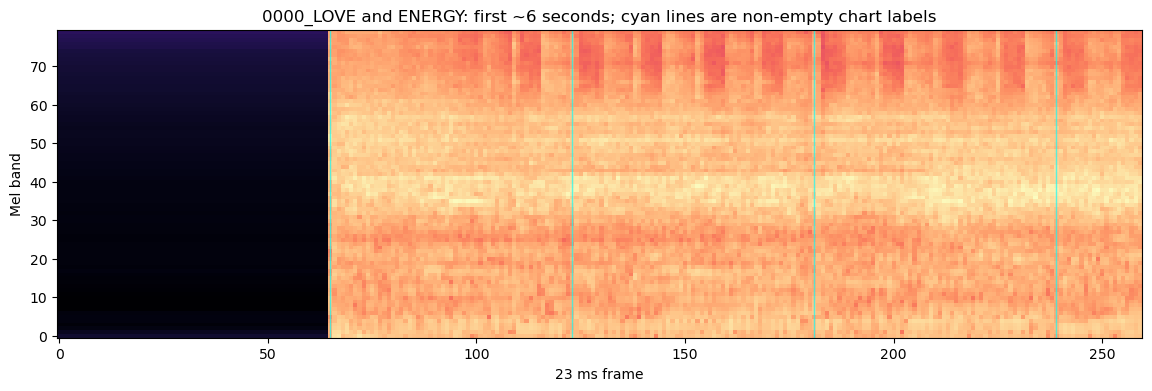

In [56]:
if RUN_PIPELINE:
    song_id = selected_rows[0]["song_id"]
    features, labels = normalized_data[song_id]
    plt.figure(figsize=(14, 4))
    plt.imshow(features[:260].T, origin="lower", aspect="auto", cmap="magma")
    for frame, cls in enumerate(labels[:260].argmax(axis=1)):
        if cls: plt.axvline(frame, color="cyan", alpha=.65, linewidth=1)
    plt.title(f"{song_id}: first ~6 seconds; cyan lines are non-empty chart labels")
    plt.xlabel("23 ms frame"); plt.ylabel("Mel band"); plt.show()
else:
    print("Visualization waits for successful extraction.")